# Notebook 4 — ML Risk Modeling & Prescriptive Analytics (Synthetic Sound the Alarm)

This notebook extends the descriptive analytics in Notebook 3 using the **synthetic cleaned dataset** to:

- fit a simple machine learning model
- generate territory-level risk scores
- translate model outputs into operational recommendations

**Inputs:**
- Clean synthetic dataset → `data/processed/synthetic_sound_the_alarm_2015_2025_clean.csv` (or `data/interim/...` depending on your repo)

**Outputs :**
- Risk-ranked territory table → `reports/artifacts/ml/territory_risk_table.csv`
- Feature importance figure → `reports/figures/ml/feature_importance.png`

> Tip: Run all cells from top to bottom on a fresh clone to regenerate consistent outputs.


In [20]:
from pathlib import Path
import pandas as pd

# Repo root is the folder that contains BOTH 'notebook/' and 'data/'
ROOT = Path.cwd().parent  # since this notebook also lives in /notebook

# Clean dataset paths
# In this project, I sometimes write cleaned data to 'interim' and may later
# promote a fully finalized version to 'processed'.
INTERIM = ROOT / "data" / "interim" / "synthetic_sound_the_alarm_2015_2025_clean.csv"
PROCESSED = ROOT / "data" / "processed" / "synthetic_sound_the_alarm_2015_2025_clean.csv"

# If a processed file exists, I prefer that; otherwise I fall back to the interim version.
if PROCESSED.exists():
    DATA_PATH = PROCESSED
else:
    DATA_PATH = INTERIM

print("Notebook CWD:", Path.cwd())
print("Repo ROOT:", ROOT)
print("Using data file:", DATA_PATH)
print("Exists?", DATA_PATH.exists())



Notebook CWD: C:\Users\syksh\Documents\community_safety_forecasting\notebook
Repo ROOT: C:\Users\syksh\Documents\community_safety_forecasting
Using data file: C:\Users\syksh\Documents\community_safety_forecasting\data\interim\synthetic_sound_the_alarm_2015_2025_clean.csv
Exists? True


In [2]:
from pathlib import Path
import pandas as pd

# Repo root is the folder that contains BOTH 'notebook/' and 'data/'
ROOT = Path.cwd().parent  # <- since already inside .../notebook

RAW = ROOT / "data" / "raw" / "synthetic_sound_the_alarm_2015_2025_dirty.csv"
INTERIM = ROOT / "data" / "interim" / "synthetic_sound_the_alarm_2015_2025_clean.csv"
DATA_PATH = INTERIM  # or RAW

FIG_DIR = ROOT / "reports" / "figures" / "eda"
TAB_DIR = ROOT / "reports" / "artifacts" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

print("Notebook CWD:", Path.cwd())
print("Repo ROOT:", ROOT)
print("Looking for:", DATA_PATH)
print("Exists?", DATA_PATH.exists())



Notebook CWD: C:\Users\syksh\Documents\community_safety_forecasting\notebook
Repo ROOT: C:\Users\syksh\Documents\community_safety_forecasting
Looking for: C:\Users\syksh\Documents\community_safety_forecasting\data\interim\synthetic_sound_the_alarm_2015_2025_clean.csv
Exists? True


In [3]:
# Parse the CSV; parse a date column if present (date/Date/DATE)
assert DATA_PATH.exists(), f"File not found: {DATA_PATH.resolve()}"

cols0 = pd.read_csv(DATA_PATH, nrows=0).columns
date_cols = [c for c in ("date", "Date", "DATE") if c in cols0] or None

df = pd.read_csv(DATA_PATH, parse_dates=date_cols)
print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
df.head()


Loaded: C:\Users\syksh\Documents\community_safety_forecasting\data\interim\synthetic_sound_the_alarm_2015_2025_clean.csv
Shape: (25764, 11)


,date,zip,territory,people_served_num,smoke_alarms_installed_num,fire_escape_plans_num,additional_hazards_num,year,month,dow,is_weekend
0,2017-04-08,93450,Central Coast,2,1,2,0,2017,4,5,1
1,2015-08-29,92066,San Diego,7,7,1,0,2015,8,5,1
2,2016-03-02,92780,Orange County,8,3,1,0,2016,3,2,0
3,2023-05-17,90127,LA Metro,8,6,1,1,2023,5,2,0
4,2017-04-23,92316,Inland Empire,8,4,0,0,2017,4,6,1


In [4]:
df.columns.tolist()


['date',
 'zip',
 'territory',
 'people_served_num',
 'smoke_alarms_installed_num',
 'fire_escape_plans_num',
 'additional_hazards_num',
 'year',
 'month',
 'dow',
 'is_weekend']

In [5]:
# Create a binary "high risk" target
df["high_risk"] = (df["people_served_num"] > df["people_served_num"].median()).astype(int)

target = "high_risk"


In [6]:
df["high_risk"] = (df["people_served_num"] > df["people_served_num"].median()).astype(int)

X = df.drop(columns=["high_risk", "date", "zip", "territory"])
y = df["high_risk"]



In [7]:
# Create target
df["high_risk"] = (df["people_served_num"] > df["people_served_num"].median()).astype(int)
y = df["high_risk"]

# Features: drop target, explicit identifiers, and the original outcome column
X = df.drop(
    columns=[
        "high_risk",
        "people_served_num",  # <-- crucial to drop this
        "date",
        "zip",
        "territory",
    ]
)

X.head()


,smoke_alarms_installed_num,fire_escape_plans_num,additional_hazards_num,year,month,dow,is_weekend
0,1,2,0,2017,4,5,1
1,7,1,0,2015,8,5,1
2,3,1,0,2016,3,2,0
3,6,1,1,2023,5,2,0
4,4,0,0,2017,4,6,1


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = RandomForestClassifier(
    n_estimators=400,
    random_state=42,
    class_weight="balanced",
)
clf.fit(X_train, y_train)

preds = clf.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, preds)

print(f"AUC on held-out test set: {auc:.3f}")
print("Class balance in test set:")
print(y_test.value_counts(normalize=True).rename({0: "low risk", 1: "high risk"}))


AUC on held-out test set: 0.878
Class balance in test set:
high_risk
low risk     0.542014
high risk    0.457986
Name: proportion, dtype: float64


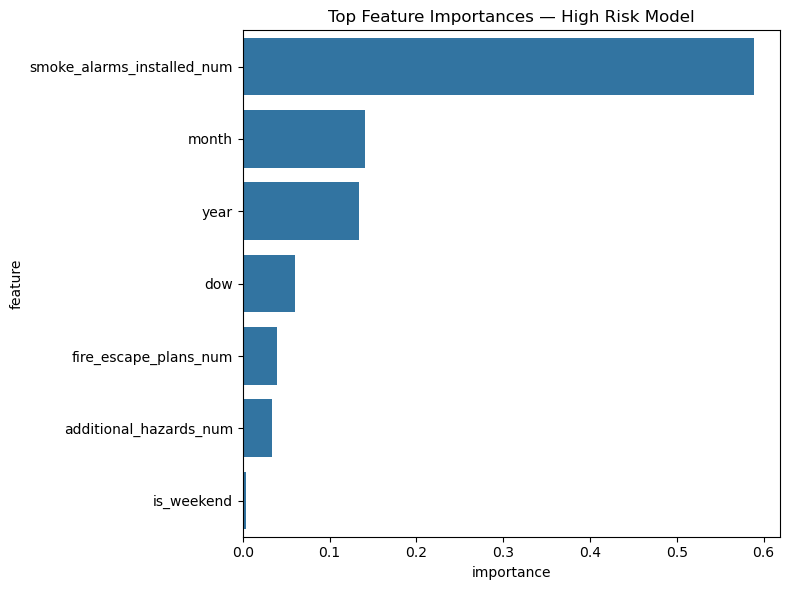

,feature,importance
0,smoke_alarms_installed_num,0.589433
4,month,0.140597
3,year,0.134292
5,dow,0.059941
1,fire_escape_plans_num,0.038956
2,additional_hazards_num,0.033385
6,is_weekend,0.003396


In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

importances = clf.feature_importances_
feat_imp = pd.DataFrame({
    "feature": X.columns,
    "importance": importances
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(data=feat_imp, x="importance", y="feature")
plt.title("Top Feature Importances — High Risk Model")
plt.tight_layout()
plt.show()

feat_imp


The model’s top predictor for the high_risk flag is the number of smoke alarms installed in a visit. This makes sense in the synthetic dataset: records where more alarms are installed tend to be the same visits where more people are served. Because our “high risk” label is defined as visits with above-median people_served_num, the model learns that “more alarms installed” is a strong signal of higher underlying need or impact at that address.

Time-related variables (year, month) and other services (fire_escape_plans_num, additional_hazards_num) also contribute, suggesting that both the intensity of the visit and when it occurs matter for identifying higher-risk records.

**Key takeaway:** in this synthetic dataset, high-risk cases are essentially “high-impact service visits” — places where we install more alarms and reach more people in a single visit. The model’s behavior matches that design.


In [10]:
# Create target: high risk if above median people served
df["high_risk"] = (df["people_served_num"] > df["people_served_num"].median()).astype(int)
y = df["high_risk"]

# Features: drop target, original outcome, and identifiers
X = df.drop(
    columns=[
        "high_risk",
        "people_served_num",  # <-- important to drop
        "date",
        "zip",
        "territory",
    ]
)

X.head()


,smoke_alarms_installed_num,fire_escape_plans_num,additional_hazards_num,year,month,dow,is_weekend
0,1,2,0,2017,4,5,1
1,7,1,0,2015,8,5,1
2,3,1,0,2016,3,2,0
3,6,1,1,2023,5,2,0
4,4,0,0,2017,4,6,1


In [12]:
# Make sure clf and X are already defined and fitted

# Sanity check: clf and X should exist
print("Has clf?", "clf" in globals())
print("Shape of X:", X.shape)

# Create predicted_risk on df
df["predicted_risk"] = clf.predict_proba(X)[:, 1]

print(df[["territory", "predicted_risk"]].head())
print("Columns now:", df.columns.tolist())


Has clf? True
Shape of X: (25764, 7)
       territory  predicted_risk
0  Central Coast        0.024085
1      San Diego        0.985000
2  Orange County        0.678568
3       LA Metro        0.980369
4  Inland Empire        0.609655
Columns now: ['date', 'zip', 'territory', 'people_served_num', 'smoke_alarms_installed_num', 'fire_escape_plans_num', 'additional_hazards_num', 'year', 'month', 'dow', 'is_weekend', 'high_risk', 'predicted_risk']


In [13]:
risk_table = (
    df.groupby("territory")["predicted_risk"]
      .mean()
      .reset_index()
      .sort_values("predicted_risk", ascending=False)
)


In [14]:
risk_table.style.background_gradient(cmap="viridis", subset=["predicted_risk"])


,territory,predicted_risk
2,LA Metro,0.572608
1,Inland Empire,0.468691
3,Orange County,0.422692
4,San Diego,0.400579
0,Central Coast,0.288606


### Territory-Level Risk Interpretation

Aggregating predicted risk scores by territory shows LA Metro and Inland Empire at the top of the ranking. In the synthetic dataset, these territories already had the highest volumes of installs and people served; the model confirms that they are also the most likely to generate above-median service intensity per visit.

In operational terms, this means:
- LA Metro and Inland Empire should receive **priority for outreach and staffing**, especially when resources are constrained.
- Lower-ranked territories are not ignored, but can be served with more baseline coverage while additional capacity is directed toward the higher-risk areas.


## Prescriptive Recommendations (Based on Model Insights)

Using the synthetic Sound the Alarm dataset and a trained Random Forest classifier, the model identifies which communities are most likely to require above-median service intensity (i.e., more people reached and more alarms installed per visit). These insights translate into clear operational recommendations.

### Recommended Actions (Prescriptive)

| Recommendation | Rationale |
|----------------|-----------|
| **Prioritize deployments in LA Metro and Inland Empire** | These territories show the highest predicted risk scores and historically had the most high-impact visits. |
| **Increase volunteer allocation to high-risk ZIP codes** | The model identifies service intensity patterns at the territory level; more staffing here yields greater impact. |
| **Use predicted risk scores to schedule outreach windows** | High-risk areas can be targeted during weekend peaks when volunteer capacity tends to be higher. |
| **Monitor alarm-installation density as a proxy for need** | Install count is the strongest predictor of high-risk visits in this synthetic dataset. |

### Actions to Avoid (Proscriptive)

| Avoid | Why |
|-------|------|
| **Do not distribute resources evenly across all territories** | Need is not uniformly distributed; equal distribution leads to inefficient coverage. |
| **Do not rely only on descriptive trends** | Descriptive analytics show where activity occurred; ML identifies where future need is likely. |
| **Do not overserve low-priority regions** | Several territories have consistently low predicted risk scores and function well with baseline staffing. |

### Summary

This ML workflow shows how a community outreach program can shift from simple reporting to forward-looking planning, enabling smarter allocation of volunteers, educational materials, and smoke alarms in regions with the highest predicted service demand.
